# Run it yourself: the robot's CNN on images from Webots

This notebook is **self-contained**: it carries the e-puck's own models and 17 images taken by the robot's camera in Webots, so it runs in Google Colab with no other files.

**To run:** *Runtime → Run all*. It takes about 30 seconds on a normal Colab CPU (no GPU needed).

What it does:
1. Unpacks the robot's **int8 TensorFlow Lite CNN** (the model used on the robot, 328 kB), the full Keras model (for Grad-CAM) and the Webots images.
2. **Detects every Webots image** with the int8 model, using the robot's own preprocessing (centre square crop, `INTER_AREA` resize to 32×32), and shows the answers.
3. Shows **Grad-CAM** heatmaps: where the CNN looked.
4. Lets you **upload any image** (for example a screenshot from Webots) and classify it.

The images come from three Webots worlds: `cnn_objects.wbt` (the object tour: truck, horse, car, deer, a paper boat on water, a green block), `animal_safari.wbt` (the eight Webots animals) and `cnn_camera_test.wbt` / `colour_blocks.wbt` (the dog and the coloured blocks).

In [1]:
#@title 1. Unpack the robot's models and the Webots images (hidden: a zip stored inside this notebook) { display-mode: "form" }
import base64, io, zipfile, pathlib
DATA = "..."
ROOT = pathlib.Path("webots_demo")
zipfile.ZipFile(io.BytesIO(base64.b64decode(DATA))).extractall(ROOT)
print("unpacked:", sorted(p.name for p in (ROOT / "images").iterdir()))

unpacked: ['animal_cat.png', 'animal_cow.png', 'animal_deer.png', 'animal_dog.png', 'animal_fox.png', 'animal_horse.png', 'animal_rabbit.png', 'animal_sheep.png', 'camera_blue_block.png', 'camera_dog.png', 'camera_red_block.png', 'tour_car.png', 'tour_deer.png', 'tour_green_block.png', 'tour_horse.png', 'tour_paper_boat_on_water.png', 'tour_truck.png']


## 2. Detect every Webots image with the robot's int8 CNN

animal_cat                   -> horse        99%   (really: cat)
animal_cow                   -> horse        96%   (really: not a CIFAR-10 class)
animal_deer                  -> deer        100%   (really: deer)
animal_dog                   -> horse        95%   (really: dog)
animal_fox                   -> deer         95%   (really: not a CIFAR-10 class)
animal_horse                 -> horse       100%   (really: horse)
animal_rabbit                -> deer         96%   (really: not a CIFAR-10 class)
animal_sheep                 -> deer         64%   (really: not a CIFAR-10 class)
camera_blue_block            -> airplane     77%   (really: not a CIFAR-10 class)
camera_dog                   -> horse        95%   (really: dog)
camera_red_block             -> cat          33%   (really: not a CIFAR-10 class)
tour_car                     -> automobile   99%   (really: automobile)
tour_deer                    -> deer        100%   (really: deer)
tour_green_block             -> bird      

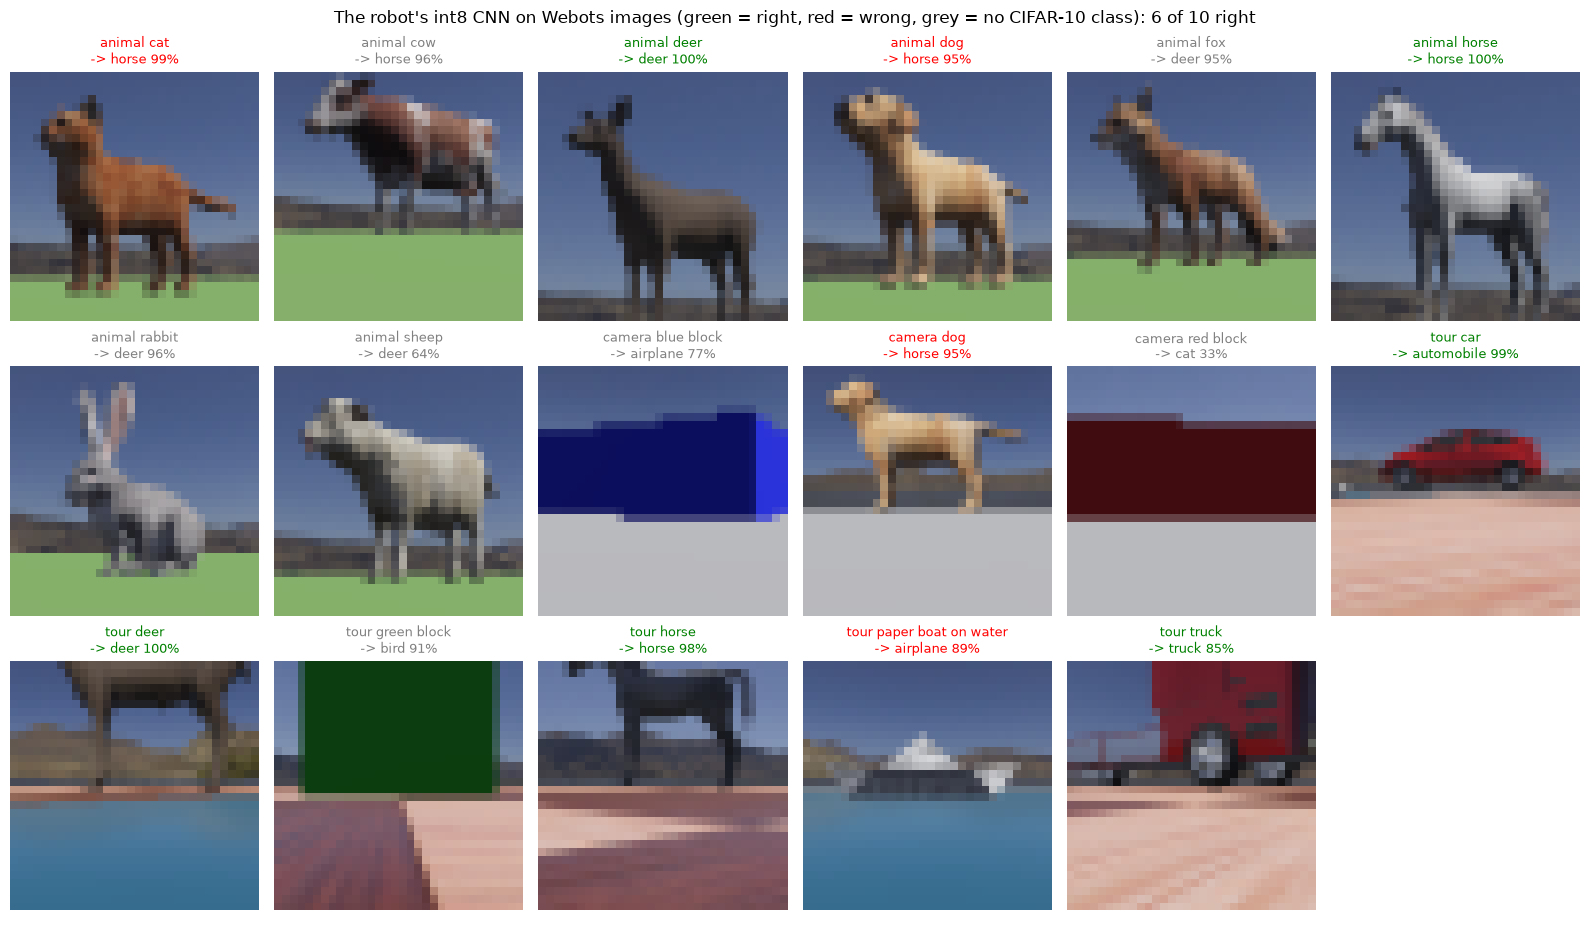

In [2]:
import numpy as np, cv2 as cv, matplotlib.pyplot as plt, tensorflow as tf

CLASS_NAMES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
# What each image really shows; "-" means CIFAR-10 has no class for it (block, cow, fox, rabbit, sheep).
TRUTH = {"tour_truck": "truck", "tour_horse": "horse", "tour_car": "automobile", "tour_paper_boat_on_water": "ship",
         "tour_deer": "deer", "tour_green_block": "-", "camera_dog": "dog", "camera_red_block": "-", "camera_blue_block": "-",
         "animal_cat": "cat", "animal_dog": "dog", "animal_deer": "deer", "animal_horse": "horse",
         "animal_cow": "-", "animal_fox": "-", "animal_rabbit": "-", "animal_sheep": "-"}

robot = tf.lite.Interpreter(model_path=str(ROOT / "cifar10_cnn_int8.tflite")); robot.allocate_tensors()
inp, out = robot.get_input_details()[0], robot.get_output_details()[0]

def to_cnn_input(path):
    """The robot's preprocessing: centre square crop, INTER_AREA resize to 32x32, RGB in [0, 1]."""
    bgr = cv.imread(str(path)); h, w = bgr.shape[:2]; s = min(h, w)
    crop = bgr[(h - s) // 2:(h - s) // 2 + s, (w - s) // 2:(w - s) // 2 + s]
    return cv.resize(cv.cvtColor(crop, cv.COLOR_BGR2RGB), (32, 32), interpolation=cv.INTER_AREA).astype(np.float32) / 255.0

def detect(x):
    scale, zero = inp["quantization"]
    robot.set_tensor(inp["index"], np.round(x[None] / scale + zero).clip(-128, 127).astype(inp["dtype"])); robot.invoke()
    q = robot.get_tensor(out["index"])[0].astype(np.float32); s, z = out["quantization"]
    logits = (q - z) * s; p = np.exp(logits - logits.max()); return p / p.sum()

paths = sorted((ROOT / "images").glob("*.png"))
fig, axes = plt.subplots(3, 6, figsize=(16, 9.5)); axes = axes.ravel()
right = known = 0
for ax, path in zip(axes, paths):
    x = to_cnn_input(path); p = detect(x); k = int(p.argmax()); truth = TRUTH[path.stem]
    if truth != "-": known += 1; right += CLASS_NAMES[k] == truth
    colour = "grey" if truth == "-" else ("green" if CLASS_NAMES[k] == truth else "red")
    ax.imshow(x); ax.axis("off")
    ax.set_title(f"{path.stem.replace('_', ' ')}\n-> {CLASS_NAMES[k]} {p[k]:.0%}", fontsize=9, color=colour)
    print(f"{path.stem:28s} -> {CLASS_NAMES[k]:10s} {p[k]:5.0%}   (really: {truth if truth != '-' else 'not a CIFAR-10 class'})")
for ax in axes[len(paths):]: ax.axis("off")
fig.suptitle(f"The robot's int8 CNN on Webots images (green = right, red = wrong, grey = no CIFAR-10 class): {right} of {known} right", fontsize=12)
plt.tight_layout(); plt.show()

## 3. Grad-CAM: where did the CNN look?

Grad-CAM needs gradients, so it uses the full Keras model of the same network (the int8 model has none). Red = most important for the answer.

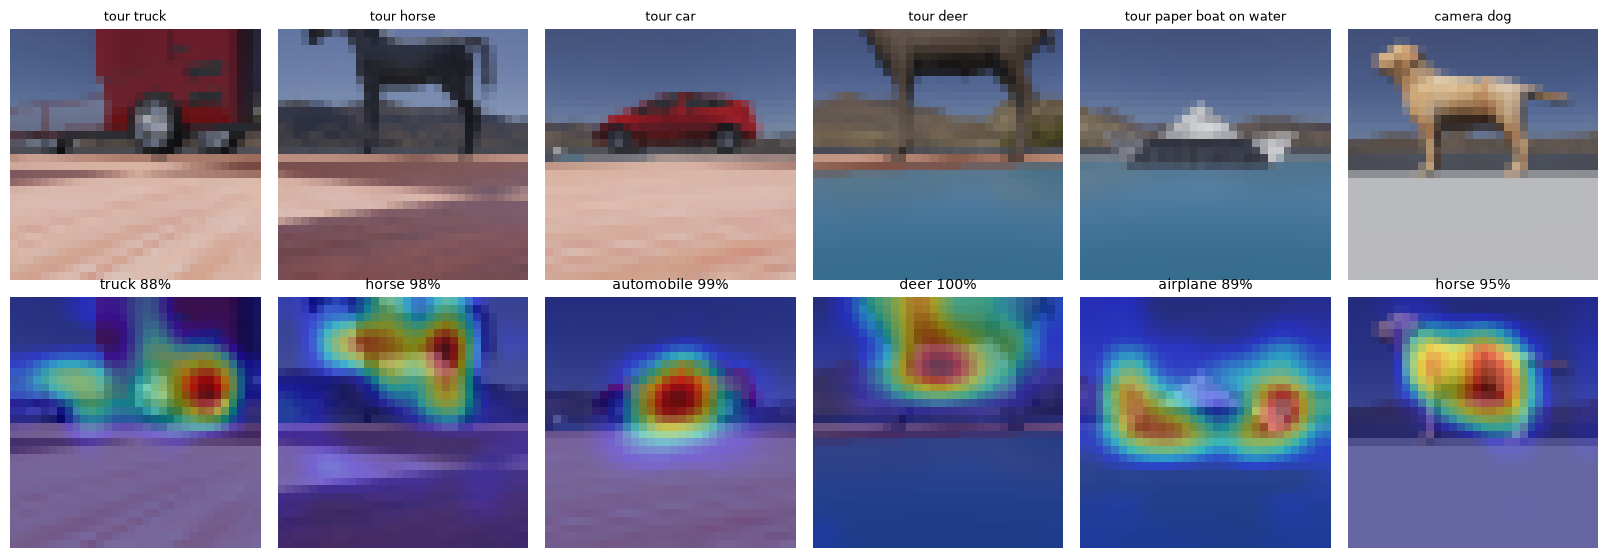

In [3]:
import json, re, warnings, zipfile, keras
warnings.filterwarnings("ignore", message="The structure of `inputs`")  # harmless Keras notice

def load_keras_model(path):
    """Load the .keras file. If this Keras is older than the one that saved it, rebuild the
    network from its config and load the trained weights. Settings that only the newer version
    knows (named in Keras's own error message) are removed one by one; none of them changes
    what the trained network computes at inference time."""
    try:
        return keras.models.load_model(path)
    except Exception:
        print(f"Loading the model for Keras {keras.__version__} (it was saved with a newer Keras): rebuilt from its layers and trained weights.")
    with zipfile.ZipFile(path) as z:
        config = json.loads(z.read("config.json")); z.extract("model.weights.h5", ROOT)
    def drop(obj, keys):
        if isinstance(obj, dict):
            for k in keys: obj.pop(k, None)
            for v in obj.values(): drop(v, keys)
        elif isinstance(obj, list):
            for v in obj: drop(v, keys)
    for attempt in range(30):
        try:
            model = keras.models.model_from_json(json.dumps(config)); break
        except Exception as e:
            msg = str(e)
            keys = re.findall(r"unexpected keyword argument '(\w+)'", msg)
            for found in re.findall(r"Unrecognized keyword arguments[^{]*(\{[^}]*\})", msg):
                keys += re.findall(r"'(\w+)':", found)
            if not keys: raise
            drop(config, set(keys))
    model.load_weights(ROOT / "model.weights.h5")
    return model

try:
    model = load_keras_model(ROOT / "cifar10_cnn.keras")
except Exception as e:  # the detection above still works without it
    model = None; print("Grad-CAM skipped: could not load the Keras model here -", type(e).__name__, str(e)[-300:])

if model is not None:
    grad_model = keras.Model(model.inputs, [model.get_layer("activation_5").output, model.output])
    def grad_cam(x):
        with tf.GradientTape() as tape:
            maps, logits = grad_model(x[None], training=False); cls = int(tf.argmax(logits[0])); score = logits[:, cls]
        w = tf.reduce_mean(tape.gradient(score, maps)[0], axis=(0, 1))
        cam = tf.nn.relu(tf.reduce_sum(maps[0] * w, axis=-1)).numpy(); cam = cv.resize(cam, (32, 32), interpolation=cv.INTER_CUBIC)
        cam = cam / cam.max() if cam.max() > 0 else cam
        return cam, cls, float(tf.nn.softmax(logits[0])[cls])
    show = ["tour_truck", "tour_horse", "tour_car", "tour_deer", "tour_paper_boat_on_water", "camera_dog"]
    fig, axes = plt.subplots(2, len(show), figsize=(2.7 * len(show), 5.6))
    for c, name in enumerate(show):
        x = to_cnn_input(ROOT / "images" / f"{name}.png"); cam, cls, prob = grad_cam(x)
        axes[0, c].imshow(x); axes[0, c].set_title(name.replace("_", " "), fontsize=9)
        axes[1, c].imshow(np.clip(0.55 * x + 0.45 * plt.cm.jet(cam)[..., :3], 0, 1)); axes[1, c].set_title(f"{CLASS_NAMES[cls]} {prob:.0%}", fontsize=10)
        for ax in axes[:, c]: ax.axis("off")
    plt.tight_layout(); plt.show()

## 4. Try your own image

This cell shows a **Choose Files** button: pick any image (a Webots screenshot, a photo of a car, an animal...) and the robot's int8 CNN classifies it with the same preprocessing. After *Run all*, the notebook waits here for a file; click **Cancel upload** to skip. (Upload works in Colab only.)

In [4]:
try:
    from google.colab import files
except ImportError:
    files = None; print("Upload needs Google Colab. Outside Colab, put an image path in classify_file(...) instead.")

def classify_file(path):
    x = to_cnn_input(path); p = detect(x); top = np.argsort(p)[::-1][:3]
    plt.figure(figsize=(3, 3)); plt.imshow(x); plt.axis("off"); plt.title(f"{CLASS_NAMES[top[0]]} {p[top[0]]:.0%}"); plt.show()
    print(path, "->", ", ".join(f"{CLASS_NAMES[i]} {p[i]:.0%}" for i in top))

if files is not None:
    for name in files.upload():
        classify_file(name)

Upload needs Google Colab. Outside Colab, put an image path in classify_file(...) instead.


## What this shows

- The robot's CNN names the Webots **truck, horse, car and deer** correctly. The Webots **cat and dog** are both called "horse", the animals CIFAR-10 has never seen get confident wrong names (cow → horse, fox and rabbit → deer): the same results as on the robot.
- The **paper boat on water** is still "airplane", and the **coloured blocks**, which are not a CIFAR-10 class, get forced into one (often "airplane"): the network has no "unknown" answer.
- Grad-CAM shows the CNN looking at the objects themselves, and at the boat's two pointed tips, like wings.